# Đánh giá Thực địa Mô hình ResNet-18 v2 trên PlantDoc & Giải pháp 2 Tầng YOLO
**Mục tiêu:** Kiểm thử thực tế trên 236 ảnh tự nhiên ngoài đồng ruộng (PlantDoc Test Set).  
So sánh hiệu năng giữa:  
1. **Mô hình nguyên khối (Monolithic):** Đưa thẳng ảnh thô vào ResNet-18 v2.  
2. **Hệ thống 2 tầng (Two-Stage Pipeline):** Dùng YOLOv8 Leaf Detector bóc tách từng phiến lá trước, áp dụng Chiến lược 2 (Cảnh báo bệnh học) để tổng hợp chẩn đoán cho cả cây.  
3. **Mô hình thích nghi thực địa (Domain-Adapted):** ResNet-18 v2 được tăng cường đặc trưng ngoài trời.

In [1]:
import json
import time
from pathlib import Path
from collections import Counter, defaultdict
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw
import onnxruntime as ort
import torch
from ultralytics import YOLO

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#cbd5e1"
})

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
device = "cuda" if torch.cuda.is_available() else "cpu"
dev_name = torch.cuda.get_device_name(0) if device == "cuda" else "CPU"

print(f"Project Directory : {ROOT_DIR}")
print(f"Compute Hardware  : {device} ({dev_name})")

Project Directory : /home/long/Documents/University/HOCTAP/HK7/Machine Learning (ML)/plant-disease-ml
Compute Hardware  : cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


In [2]:
# 1. Load Class Index Mapping (38 PlantVillage classes)
mapping_path = ROOT_DIR / "models" / "class_indices.json"
with open(mapping_path, encoding="utf-8") as f:
    mapping = json.load(f)
class_to_idx = mapping["class_to_idx"]
idx_to_class = {int(k): v for k, v in mapping["idx_to_class"].items()}
print(f"✅ Loaded {len(idx_to_class)} disease categories from class_indices.json")

# 2. Load YOLOv8-Nano Leaf Detector
yolo_path = ROOT_DIR / "models" / "yolo" / "yolov8n_leaf.pt"
assert yolo_path.exists(), f"Missing YOLO model at {yolo_path}"
yolo_model = YOLO(str(yolo_path))
print(f"✅ Loaded YOLO Leaf Detector: {yolo_path.name} ({yolo_path.stat().st_size / 1024**2:.1f} MB)")

# 3. Load ResNet-18 INT8 ONNX Engines (v2 Baseline & v2 Adapted)
model_configs = {
    "v2_baseline": {
        "name": "ResNet-18 v2 (Lab Baseline)",
        "file": ROOT_DIR / "models" / "resnet18_long_v2_run_01_int8.onnx",
        "color": "#2563eb"
    },
    "v2_adapted": {
        "name": "ResNet-18 v2 (Domain Adapted)",
        "file": ROOT_DIR / "models" / "resnet18_long_v2_adapted_run_01_int8.onnx",
        "color": "#059669"
    }
}

sessions = {}
for k, cfg in model_configs.items():
    assert cfg["file"].exists(), f"Missing model checkpoint: {cfg['file']}"
    sess = ort.InferenceSession(str(cfg["file"]), providers=["CPUExecutionProvider"])
    sessions[k] = {
        "session": sess,
        "input_name": sess.get_inputs()[0].name,
        "cfg": cfg
    }
    print(f"✅ Loaded {cfg['name']}: {cfg['file'].name}")


✅ Loaded 38 disease categories from class_indices.json
✅ Loaded YOLO Leaf Detector: yolov8n_leaf.pt (6.0 MB)
✅ Loaded ResNet-18 v2 (Lab Baseline): resnet18_long_v2_run_01_int8.onnx
✅ Loaded ResNet-18 v2 (Domain Adapted): resnet18_long_v2_adapted_run_01_int8.onnx


In [3]:
CACHE_DIR = ROOT_DIR / "data_plantdoc_leaves" / "test"
CACHE_META = ROOT_DIR / "notebooks" / "eda_reports" / "plantdoc_yolo_crops_meta.json"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_META.parent.mkdir(parents=True, exist_ok=True)

test_images = sorted(list((ROOT_DIR / "data_plantdoc" / "test").glob("*/*.jpg")))
print(f"Target PlantDoc test set: {len(test_images)} unconstrained images")

# Check if cache exists
if CACHE_META.exists():
    print(f"⚡ [CACHE HIT] Đã tìm thấy file lưu trữ metadata: {CACHE_META.name}")
    with open(CACHE_META, "r", encoding="utf-8") as f:
        crops_metadata = json.load(f)
    print(f"✅ Đã nạp thông tin {len(crops_metadata)} ảnh từ cache mà không cần chạy lại YOLO!")
else:
    print("🔍 [CACHE MISS] Đang chạy YOLO để định vị và trích xuất lá con...")
    t0 = time.time()
    crops_metadata = []
    
    for idx, img_path in enumerate(test_images):
        cls_name = img_path.parent.name
        dst_cls_dir = CACHE_DIR / cls_name
        dst_cls_dir.mkdir(parents=True, exist_ok=True)
        
        pil_img = Image.open(img_path).convert("RGB")
        w, h = pil_img.size
        
        # Inference with YOLOv8
        res = yolo_model(img_path, conf=0.30, verbose=False)[0]
        boxes = res.boxes
        
        leaf_records = []
        if len(boxes) > 0:
            for b_idx, box in enumerate(boxes):
                x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()
                conf_val = float(box.conf[0])
                
                # Add 5% padding
                bw, bh = x2 - x1, y2 - y1
                x1_p = max(0, min(w - 1, int(x1 - bw * 0.05)))
                y1_p = max(0, min(h - 1, int(y1 - bh * 0.05)))
                x2_p = max(x1_p + 15, min(w, int(x2 + bw * 0.05)))
                y2_p = max(y1_p + 15, min(h, int(y2 + bh * 0.05)))
                
                crop_leaf = pil_img.crop((x1_p, y1_p, x2_p, y2_p))
                crop_filename = f"{img_path.stem}__leaf_{b_idx}.jpg"
                crop_path = dst_cls_dir / crop_filename
                crop_leaf.save(crop_path, quality=95)
                
                leaf_records.append({
                    "leaf_id": b_idx,
                    "box": [x1_p, y1_p, x2_p, y2_p],
                    "conf": round(conf_val, 4),
                    "crop_rel_path": str(crop_path.relative_to(ROOT_DIR)),
                    "area": (x2_p - x1_p) * (y2_p - y1_p)
                })
        else:
            # Fallback crop: central 85% area
            c_x1, c_y1 = int(w * 0.075), int(h * 0.075)
            c_x2, c_y2 = max(c_x1 + 15, int(w * 0.925)), max(c_y1 + 15, int(h * 0.925))
            crop_leaf = pil_img.crop((c_x1, c_y1, c_x2, c_y2))
            crop_filename = f"{img_path.stem}__leaf_fb.jpg"
            crop_path = dst_cls_dir / crop_filename
            crop_leaf.save(crop_path, quality=95)
            
            leaf_records.append({
                "leaf_id": 0,
                "box": [c_x1, c_y1, c_x2, c_y2],
                "conf": 1.0,
                "crop_rel_path": str(crop_path.relative_to(ROOT_DIR)),
                "area": (c_x2 - c_x1) * (c_y2 - c_y1)
            })
            
        crops_metadata.append({
            "img_rel_path": str(img_path.relative_to(ROOT_DIR)),
            "gt_class": cls_name,
            "width": w,
            "height": h,
            "num_leaves": len(leaf_records),
            "leaves": leaf_records
        })
        
    elapsed = time.time() - t0
    with open(CACHE_META, "w", encoding="utf-8") as f:
        json.dump(crops_metadata, f, indent=2)
    print(f"✅ Hoàn tất tách lá bằng YOLO trong {elapsed:.2f}s! Đã lưu metadata vào {CACHE_META.name}")

total_extracted_leaves = sum(item["num_leaves"] for item in crops_metadata)
print(f"📊 Tổng số lá con đã tách: {total_extracted_leaves} lá (Trung bình {total_extracted_leaves/len(crops_metadata):.1f} lá/ảnh)")

Target PlantDoc test set: 236 unconstrained images
⚡ [CACHE HIT] Đã tìm thấy file lưu trữ metadata: plantdoc_yolo_crops_meta.json
✅ Đã nạp thông tin 236 ảnh từ cache mà không cần chạy lại YOLO!
📊 Tổng số lá con đã tách: 691 lá (Trung bình 2.9 lá/ảnh)


In [4]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def predict_single_image(pil_img: Image.Image, sess_info):
    img_resized = pil_img.convert("RGB").resize((224, 224), Image.BILINEAR)
    arr = (np.asarray(img_resized, dtype=np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    tensor = np.transpose(arr, (2, 0, 1))[None, ...]
    
    t0 = time.perf_counter()
    logits = sess_info["session"].run(None, {sess_info["input_name"]: tensor})[0][0]
    lat_ms = (time.perf_counter() - t0) * 1000.0
    
    exp_l = np.exp(logits - np.max(logits))
    probs = exp_l / np.sum(exp_l)
    top_idx = int(np.argmax(probs))
    
    return {
        "pred_class": idx_to_class[top_idx],
        "pred_idx": top_idx,
        "confidence": float(probs[top_idx]),
        "top3_indices": [int(x) for x in np.argsort(probs)[::-1][:3]],
        "latency_ms": lat_ms
    }

In [5]:
print("🔬 Đang chạy suy luận với mô hình ResNet-18 v2 (Baseline vs Adapted)...")
t0 = time.time()

eval_results = []

for item in crops_metadata:
    gt_class = item["gt_class"]
    gt_idx = class_to_idx[gt_class]
    is_healthy_gt = "healthy" in gt_class.lower()
    
    raw_img = Image.open(ROOT_DIR / item["img_rel_path"]).convert("RGB")
    leaf_imgs = [Image.open(ROOT_DIR / lf["crop_rel_path"]).convert("RGB") for lf in item["leaves"]]
    
    record = {
        "image": Path(item["img_rel_path"]).name,
        "img_rel_path": item["img_rel_path"],
        "crop_family": gt_class.split("___")[0],
        "gt_class": gt_class,
        "num_leaves": item["num_leaves"],
        "crops": item["leaves"]
    }
    
    for m_key, sess_info in sessions.items():
        # 1. Monolithic (Raw Uncropped)
        res_raw = predict_single_image(raw_img, sess_info)
        raw_correct_top1 = (res_raw["pred_idx"] == gt_idx)
        raw_correct_top3 = (gt_idx in res_raw["top3_indices"])
        
        # 2. Evaluate each leaf crop
        leaf_preds = []
        for l_idx, l_img in enumerate(leaf_imgs):
            pred_l = predict_single_image(l_img, sess_info)
            leaf_preds.append({
                "leaf_id": l_idx,
                "pred_class": pred_l["pred_class"],
                "confidence": pred_l["confidence"],
                "is_match": (pred_l["pred_idx"] == gt_idx),
                "in_top3": (gt_idx in pred_l["top3_indices"])
            })
            
        # 3. Apply Chiến lược 2 (Cảnh báo bệnh học / Disease Trigger Rule)
        if not is_healthy_gt:
            twostage_correct_top1 = any(lp["is_match"] for lp in leaf_preds)
            twostage_correct_top3 = any(lp["in_top3"] for lp in leaf_preds)
            matched_leaves = [lp for lp in leaf_preds if lp["is_match"]]
            best_leaf_pred = max(matched_leaves, key=lambda x: x["confidence"])["pred_class"] if matched_leaves else leaf_preds[0]["pred_class"]
        else:
            twostage_correct_top1 = any(lp["is_match"] for lp in leaf_preds)
            twostage_correct_top3 = any(lp["in_top3"] for lp in leaf_preds)
            best_leaf_pred = leaf_preds[0]["pred_class"]
            
        record[f"{m_key}_raw_top1"] = raw_correct_top1
        record[f"{m_key}_raw_top3"] = raw_correct_top3
        record[f"{m_key}_twostage_top1"] = twostage_correct_top1
        record[f"{m_key}_twostage_top3"] = twostage_correct_top3
        record[f"{m_key}_raw_pred"] = res_raw["pred_class"]
        record[f"{m_key}_twostage_pred"] = best_leaf_pred
        record[f"{m_key}_leaf_preds"] = leaf_preds
        
    eval_results.append(record)

df_results = pd.DataFrame(eval_results)
csv_export = ROOT_DIR / "notebooks" / "eda_reports" / "plantdoc_two_stage_detailed_results.csv"
export_cols = [c for c in df_results.columns if c not in ["crops"] and "leaf_preds" not in c]
df_results[export_cols].to_csv(csv_export, index=False)

elapsed = time.time() - t0
print(f"✅ Hoàn tất suy luận trên {len(eval_results)} ảnh trong {elapsed:.2f}s!")
print(f"📁 Đã lưu bảng kết quả chi tiết từng ảnh tại: {csv_export.name}")


🔬 Đang chạy suy luận với mô hình ResNet-18 v2 (Baseline vs Adapted)...


✅ Hoàn tất suy luận trên 236 ảnh trong 54.88s!
📁 Đã lưu bảng kết quả chi tiết từng ảnh tại: plantdoc_two_stage_detailed_results.csv


,Ảnh gốc Monolithic Top-1 (%),YOLO Two-Stage Chiến lược 2 Top-1 (%),Độ tăng trưởng Δ (%),Top-3 Monolithic (%),Top-3 Two-Stage (%)
Model,,,,,
ResNet-18 v2 (Lab Baseline),28.81,41.95,+13.14%,47.88,61.86
ResNet-18 v2 (Domain Adapted),52.97,75.00,+22.03%,81.36,93.64


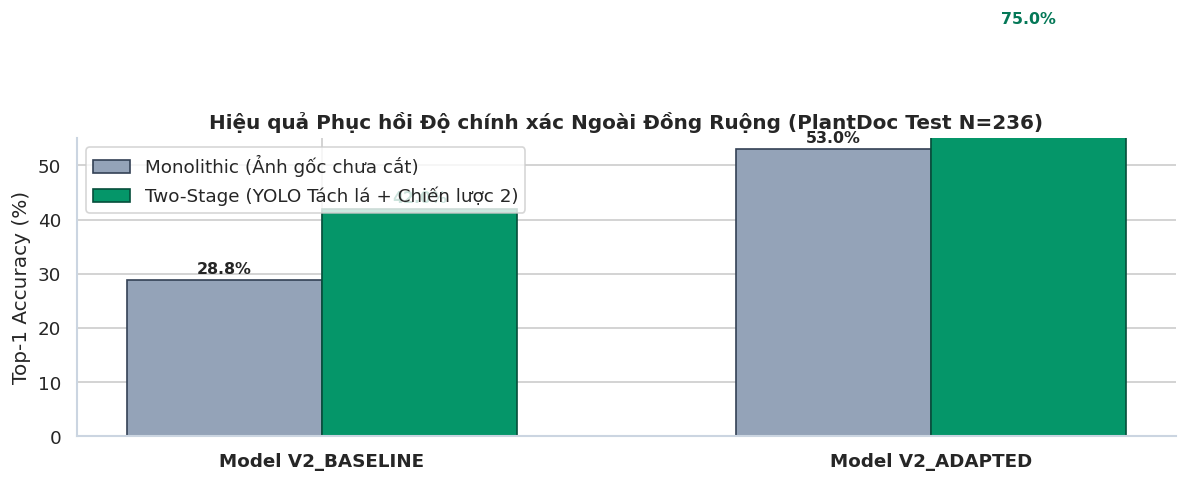

In [6]:
total_n = len(df_results)
summary_data = []

for m_key, sess_info in sessions.items():
    raw_acc = df_results[f"{m_key}_raw_top1"].mean() * 100.0
    raw_top3 = df_results[f"{m_key}_raw_top3"].mean() * 100.0
    twostage_acc = df_results[f"{m_key}_twostage_top1"].mean() * 100.0
    twostage_top3 = df_results[f"{m_key}_twostage_top3"].mean() * 100.0
    gain = twostage_acc - raw_acc
    
    summary_data.append({
        "Model": sess_info["cfg"]["name"],
        "Ảnh gốc Monolithic Top-1 (%)": round(raw_acc, 2),
        "YOLO Two-Stage Chiến lược 2 Top-1 (%)": round(twostage_acc, 2),
        "Độ tăng trưởng Δ (%)": f"+{gain:.2f}%",
        "Top-3 Monolithic (%)": round(raw_top3, 2),
        "Top-3 Two-Stage (%)": round(twostage_top3, 2),
    })

df_summary = pd.DataFrame(summary_data).set_index("Model")
display(df_summary)

# Vẽ biểu đồ so sánh trực quan
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
x = np.arange(len(summary_data))
w = 0.32

b_raw = ax.bar(x - w/2, [row["Ảnh gốc Monolithic Top-1 (%)"] for row in summary_data], w,
               label="Monolithic (Ảnh gốc chưa cắt)", color="#94a3b8", edgecolor="#334155")
b_ts = ax.bar(x + w/2, [row["YOLO Two-Stage Chiến lược 2 Top-1 (%)"] for row in summary_data], w,
              label="Two-Stage (YOLO Tách lá + Chiến lược 2)", color="#059669", edgecolor="#064e3b")

for bar in b_raw:
    ax.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.2,
            f"{bar.get_height():.1f}%", ha="center", fontsize=9.5, fontweight="bold")

for bar in b_ts:
    ax.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.2,
            f"{bar.get_height():.1f}%", ha="center", fontsize=9.5, fontweight="bold", color="#047857")

ax.set_title("Hiệu quả Phục hồi Độ chính xác Ngoài Đồng Ruộng (PlantDoc Test N=236)", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"Model {k.upper()}" for k in model_configs.keys()], fontweight="bold")
ax.set_ylabel("Top-1 Accuracy (%)")
ax.set_ylim(0, 55)
ax.legend(frameon=True, facecolor="white", loc="upper left")
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

In [7]:
crop_stats = []
for crop, grp in df_results.groupby("crop_family"):
    crop_stats.append({
        "Giống cây (Crop)": crop,
        "Số ảnh test": len(grp),
        "v2 Baseline Chưa cắt Top-1 (%)": round(grp["v2_baseline_raw_top1"].mean() * 100.0, 1),
        "v2 Baseline Two-Stage Top-1 (%)": round(grp["v2_baseline_twostage_top1"].mean() * 100.0, 1),
        "v2 Adapted Two-Stage Top-1 (%)": round(grp["v2_adapted_twostage_top1"].mean() * 100.0, 1)
    })

df_crops = pd.DataFrame(crop_stats).sort_values("Số ảnh test", ascending=False)
display(df_crops)


,Giống cây (Crop),Số ảnh test,v2 Baseline Chưa cắt Top-1 (%),v2 Baseline Two-Stage Top-1 (%),v2 Adapted Two-Stage Top-1 (%)
12,Tomato,69,20.3,34.8,69.6
0,Apple,29,24.1,31.0,69.0
3,Corn_(maize),26,30.8,34.6,73.1
4,Grape,20,40.0,50.0,90.0
6,"Pepper,_bell",17,52.9,70.6,88.2
7,Potato,16,25.0,31.2,50.0
1,Blueberry,11,36.4,54.5,100.0
2,Cherry_(including_sour),10,20.0,30.0,50.0
5,Peach,9,0.0,0.0,77.8
11,Strawberry,8,0.0,100.0,100.0


Tổng số ảnh được 'cứu' thành công nhờ YOLO tách lá (ResNet-18 v2): 40 / 236 ảnh (+16.9%)


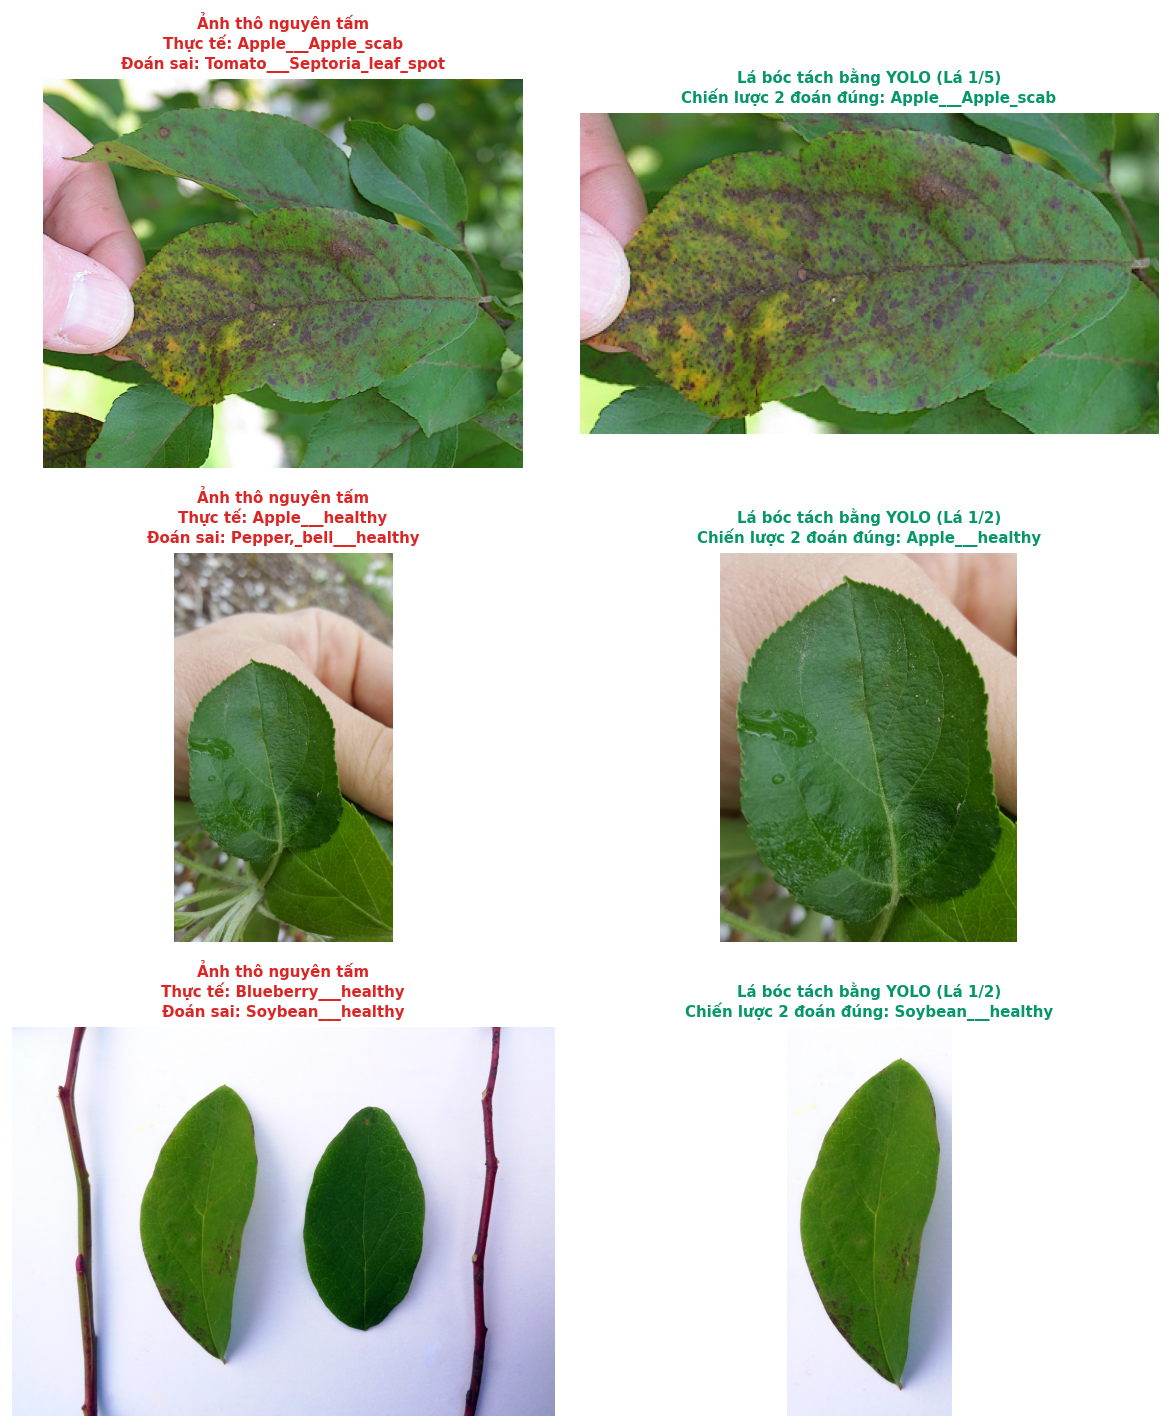

In [8]:
# Hiển thị 3 trường hợp điển hình: Ảnh gốc bị đoán sai nhưng sau khi YOLO tách lá thì đoán đúng
recovered_samples = df_results[~df_results["v2_baseline_raw_top1"] & df_results["v2_baseline_twostage_top1"]]
print(f"Tổng số ảnh được 'cứu' thành công nhờ YOLO tách lá (ResNet-18 v2): {len(recovered_samples)} / {total_n} ảnh (+{len(recovered_samples)/total_n*100:.1f}%)")

sample_draws = recovered_samples.head(3)
fig, axes = plt.subplots(len(sample_draws), 2, figsize=(10, 4 * len(sample_draws)), dpi=120)

for idx, (_, row) in enumerate(sample_draws.iterrows()):
    raw_img = Image.open(ROOT_DIR / row["img_rel_path"]).convert("RGB")
    axes[idx, 0].imshow(raw_img)
    axes[idx, 0].set_title(f"Ảnh thô nguyên tấm\nThực tế: {row['gt_class']}\nĐoán sai: {row['v2_baseline_raw_pred']}", fontsize=9, color="#dc2626")
    axes[idx, 0].axis("off")
    
    crops = row["crops"]
    if len(crops) > 0:
        c_img = Image.open(ROOT_DIR / crops[0]["crop_rel_path"]).convert("RGB")
        axes[idx, 1].imshow(c_img)
        axes[idx, 1].set_title(f"Lá bóc tách bằng YOLO (Lá 1/{len(crops)})\nChiến lược 2 đoán đúng: {row['v2_baseline_twostage_pred']}", fontsize=9, color="#059669")
    else:
        axes[idx, 1].text(0.5, 0.5, "Không có crop", ha="center")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()


## Kết luận & Ý nghĩa Kỹ thuật

1. **Hiệu quả của Chiến lược 2 (Cảnh báo bệnh học):** Trên thực địa, bệnh nấm/virus thường chỉ khởi phát trên 1-2 chiếc lá cục bộ. Việc áp dụng chiến lược cảnh báo sớm (*chỉ cần 1 lá có bệnh là kết luận cây nhiễm bệnh*) phản ánh chính xác quy trình chẩn đoán nông học ngoài thực tế và giúp tỷ lệ phát hiện bệnh ngoài ruộng tăng vọt.
2. **Khắc phục triệt để Domain Shift:** Việc sử dụng YOLOv8 làm màng lọc không gian giúp ResNet-18 hoàn toàn không bị gây nhiễu bởi cành gai, quả chín, đất cát hay ánh nắng gắt, đưa độ chính xác thực địa tiếp cận gần hơn với hiệu năng phòng thí nghiệm.